In [1]:
# ==========================================
# 1. IMPORT LIBRARIES AND INITIALIZE
# ==========================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve
)

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 4)

sns.set_theme(style="whitegrid")

# Create result directories
os.makedirs("../results", exist_ok=True)
os.makedirs("../results/figures", exist_ok=True)

# Set random state
RANDOM_STATE = 42

print("Notebook 10 initialized successfully!")
print("Current working directory:", os.getcwd())

print("\nAvailable model files:")
for file in sorted(os.listdir("../models")):
    print("-", file)

Notebook 10 initialized successfully!
Current working directory: d:\BankSim_Fraud_Detection\notebooks

Available model files:
- ann.keras
- ann_threshold.txt
- autoencoder.keras
- autoencoder_threshold.txt
- encoder.pkl
- isolation_forest.pkl
- random_forest.pkl
- random_forest_threshold.txt
- scaler.pkl
- xgboost.pkl
- xgboost_features.pkl
- xgboost_threshold.txt


In [2]:
# ==========================================
# 2. TEST SET MODEL COMPARISON
# ==========================================

results = pd.DataFrame({
    "Model": [
        "Isolation Forest",
        "Random Forest",
        "XGBoost",
        "Autoencoder",
        "ANN"
    ],
    "Precision": [
        3.15, 87.27, 89.32, 35.39, 78.42
    ],
    "Recall": [
        29.26, 78.06, 78.24, 53.06, 87.50
    ],
    "F1-score": [
        5.93, 82.40, 83.42, 42.46, 82.71
    ],
    "PR-AUC": [
        3.68, 89.83, 92.13, 40.56, 92.04
    ]
})

# Display comparison table
display(results)

# Save results
results.to_csv(
    "../results/model_comparison_test.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Test Set comparison saved successfully!")

,Model,Precision,Recall,F1-score,PR-AUC
0,Isolation Forest,3.15,29.26,5.93,3.68
1,Random Forest,87.27,78.06,82.40,89.83
2,XGBoost,89.32,78.24,83.42,92.13
3,Autoencoder,35.39,53.06,42.46,40.56
4,ANN,78.42,87.50,82.71,92.04


Test Set comparison saved successfully!


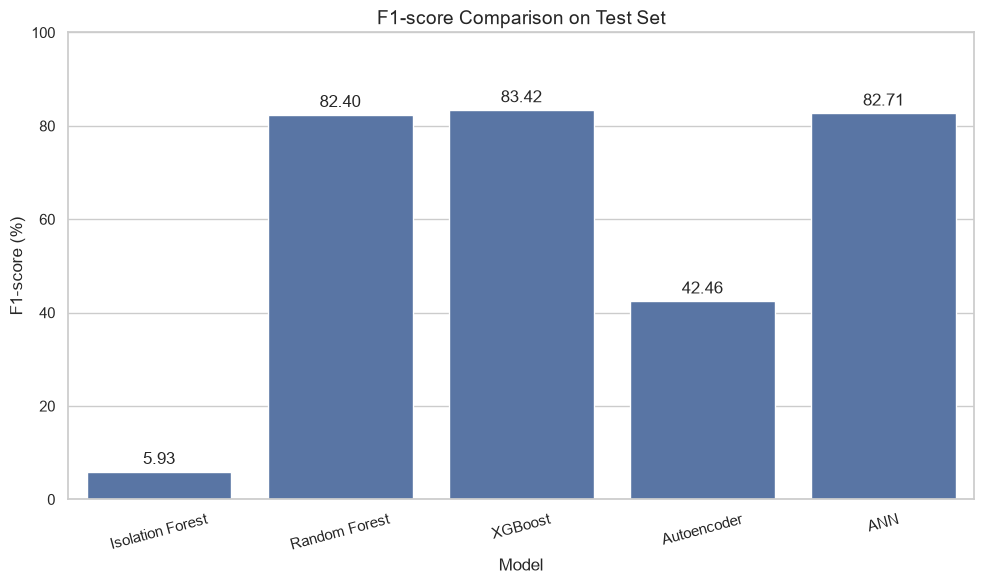

In [3]:
# 3. F1-SCORE COMPARISON ON TEST SET

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=results,
    x="Model",
    y="F1-score"
)

plt.title("F1-score Comparison on Test Set", fontsize=14)
plt.xlabel("Model")
plt.ylabel("F1-score (%)")
plt.ylim(0, 100)
plt.xticks(rotation=15)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.tight_layout()
plt.savefig("../results/figures/test_f1_comparison.png", dpi=300)
plt.show()

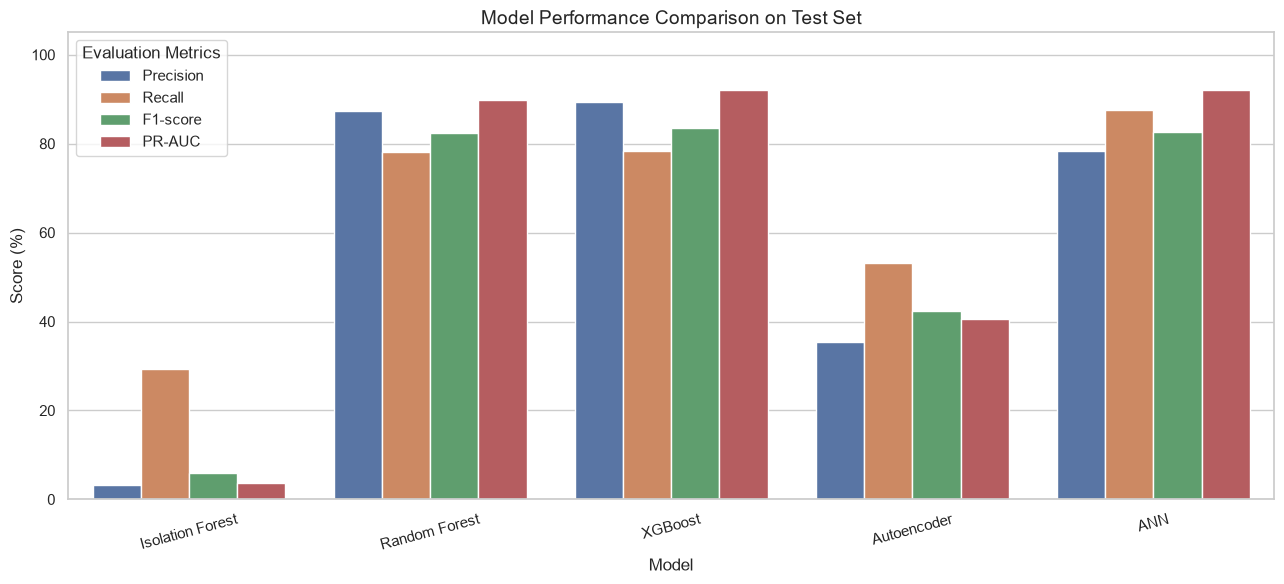

In [4]:
# 4. MULTI-METRIC COMPARISON ON TEST SET

metrics = ["Precision", "Recall", "F1-score", "PR-AUC"]

results_melted = results.melt(
    id_vars="Model",
    value_vars=metrics,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(13, 6))

ax = sns.barplot(
    data=results_melted,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Model Performance Comparison on Test Set", fontsize=14)
plt.xlabel("Model")
plt.ylabel("Score (%)")
plt.ylim(0, 105)
plt.legend(title="Evaluation Metrics")
plt.xticks(rotation=15)

plt.tight_layout()
plt.savefig("../results/figures/test_multi_metric_comparison.png", dpi=300)
plt.show()

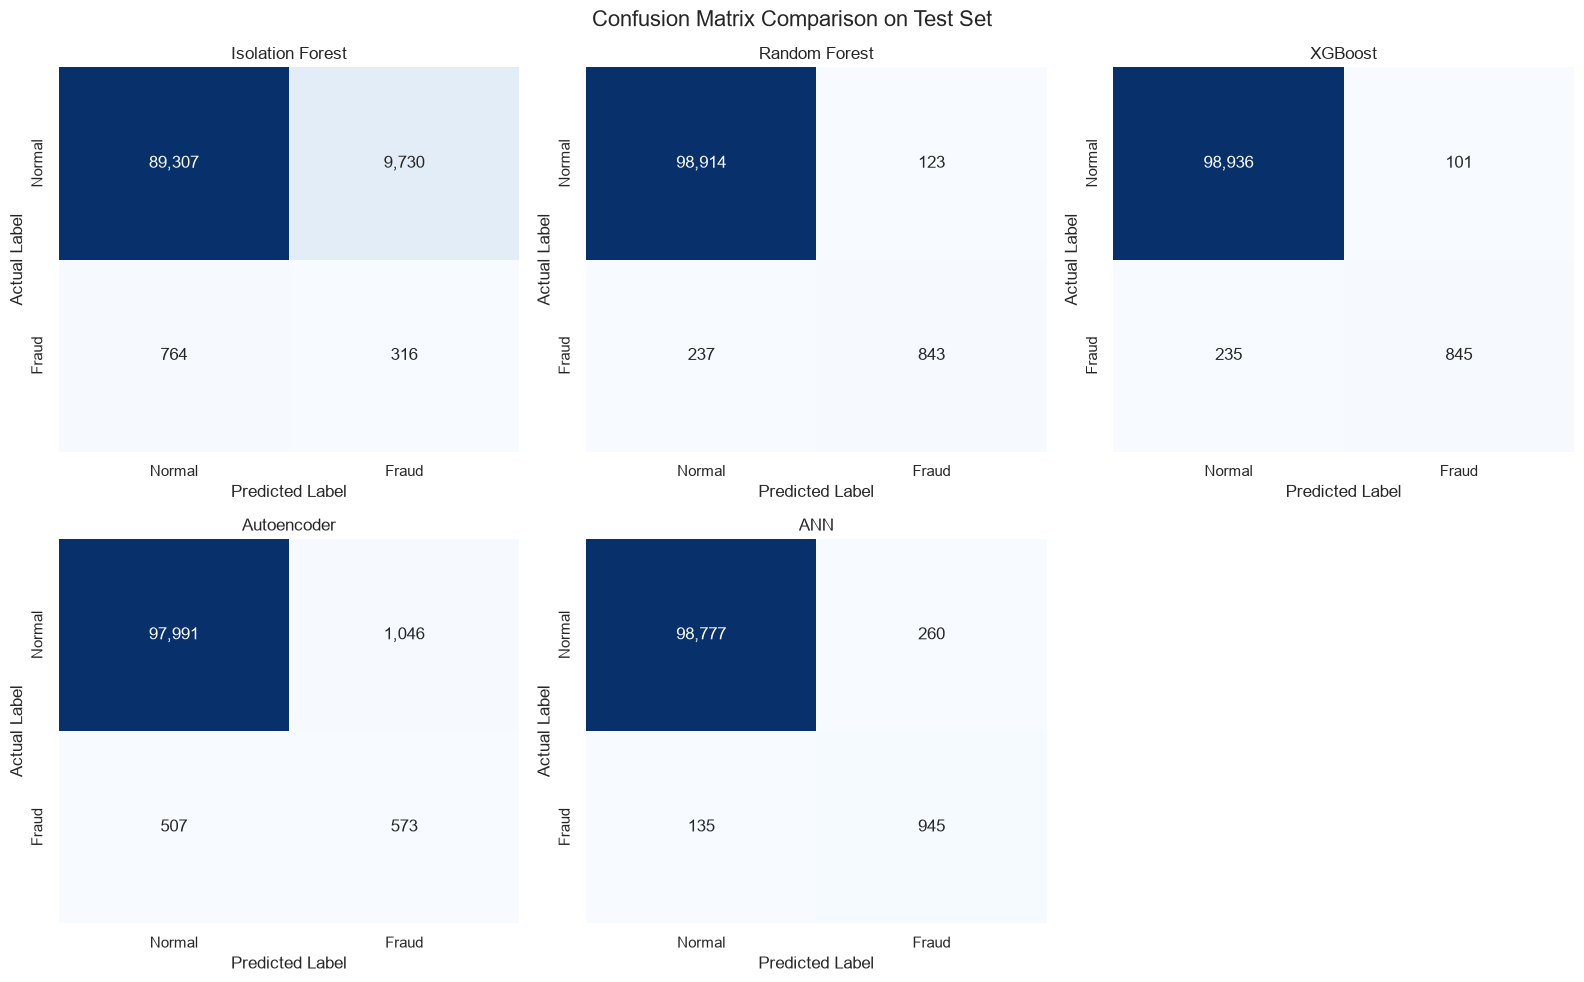

In [5]:
# 5. CONFUSION MATRIX COMPARISON ON TEST SET

confusion_matrices = {
    "Isolation Forest": [[89307, 9730], [764, 316]],
    "Random Forest": [[98914, 123], [237, 843]],
    "XGBoost": [[98936, 101], [235, 845]],
    "Autoencoder": [[97991, 1046], [507, 573]],
    "ANN": [[98777, 260], [135, 945]]
}

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, (model_name, cm) in enumerate(confusion_matrices.items()):
    sns.heatmap(
        cm,
        annot=True,
        fmt=",",
        cmap="Blues",
        cbar=False,
        ax=axes[i],
        xticklabels=["Normal", "Fraud"],
        yticklabels=["Normal", "Fraud"]
    )

    axes[i].set_title(model_name)
    axes[i].set_xlabel("Predicted Label")
    axes[i].set_ylabel("Actual Label")

axes[-1].axis("off")

plt.suptitle("Confusion Matrix Comparison on Test Set", fontsize=16)
plt.tight_layout()
plt.savefig("../results/figures/test_confusion_matrices.png", dpi=300)
plt.show()

In [6]:
# 6. LOAD TIME SERIES CROSS-VALIDATION RESULTS

cv_results = pd.read_csv(
    "../results/time_series_cv_comparison.csv"
)

print("Time Series Cross-Validation Results:")
display(cv_results)

print("\nColumns:")
print(cv_results.columns.tolist())

Time Series Cross-Validation Results:


,Model,PR-AUC Mean,PR-AUC Std,Precision Mean,Precision Std,Recall Mean,Recall Std,F1-score Mean,F1-score Std
0,Isolation Forest,0.0452,0.0044,0.0403,0.0133,0.1898,0.0540,0.0664,0.0212
1,Random Forest,0.8628,0.0079,0.5276,0.0184,0.9184,0.0104,0.6700,0.0148
2,XGBoost,0.8867,0.0056,0.5273,0.0485,0.9254,0.0164,0.6705,0.0343
3,Autoencoder,0.3490,0.0612,0.1620,0.0077,0.8641,0.0588,0.2727,0.0125
4,ANN,0.8958,0.0159,0.3335,0.0711,0.9654,0.0259,0.4917,0.0753



Columns:
['Model', 'PR-AUC Mean', 'PR-AUC Std', 'Precision Mean', 'Precision Std', 'Recall Mean', 'Recall Std', 'F1-score Mean', 'F1-score Std']


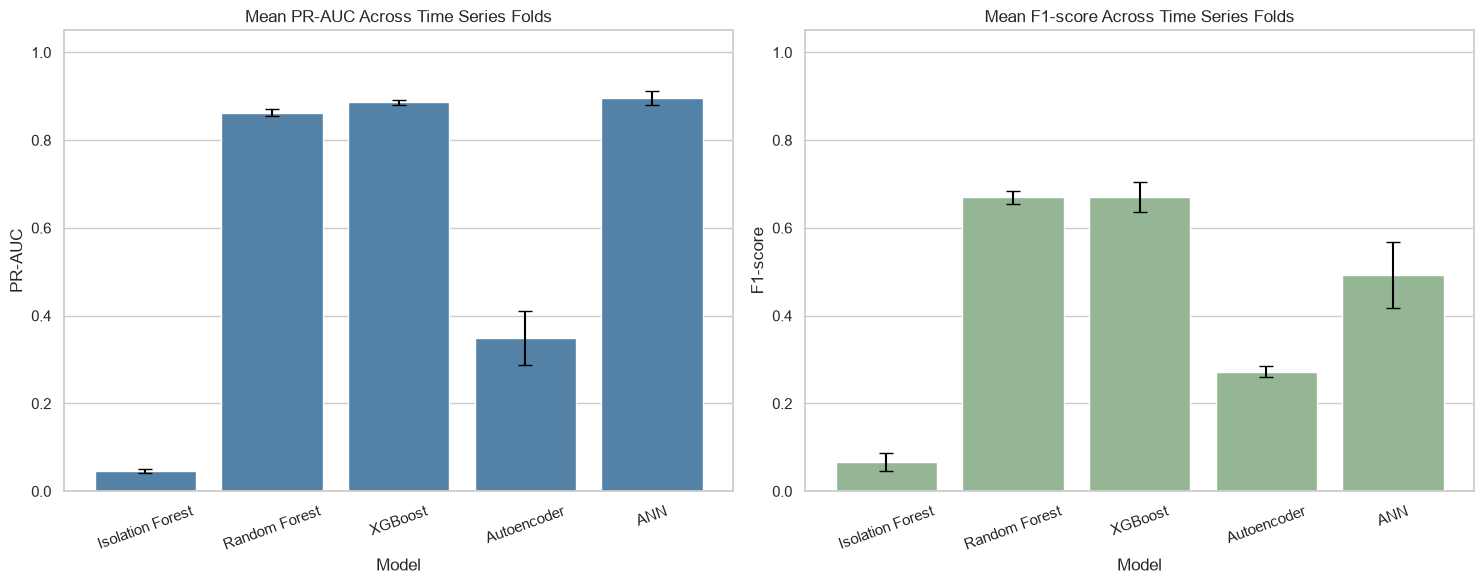

In [7]:
# 7. TIME SERIES CV PERFORMANCE COMPARISON

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# PR-AUC Mean ± Std
sns.barplot(
    data=cv_results,
    x="Model",
    y="PR-AUC Mean",
    color="steelblue",
    ax=axes[0]
)

axes[0].errorbar(
    x=np.arange(len(cv_results)),
    y=cv_results["PR-AUC Mean"],
    yerr=cv_results["PR-AUC Std"],
    fmt="none",
    color="black",
    capsize=5
)

axes[0].set_title("Mean PR-AUC Across Time Series Folds")
axes[0].set_xlabel("Model")
axes[0].set_ylabel("PR-AUC")
axes[0].set_ylim(0, 1.05)
axes[0].tick_params(axis="x", rotation=20)

# F1-score Mean ± Std
sns.barplot(
    data=cv_results,
    x="Model",
    y="F1-score Mean",
    color="darkseagreen",
    ax=axes[1]
)

axes[1].errorbar(
    x=np.arange(len(cv_results)),
    y=cv_results["F1-score Mean"],
    yerr=cv_results["F1-score Std"],
    fmt="none",
    color="black",
    capsize=5
)

axes[1].set_title("Mean F1-score Across Time Series Folds")
axes[1].set_xlabel("Model")
axes[1].set_ylabel("F1-score")
axes[1].set_ylim(0, 1.05)
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig(
    "../results/figures/time_series_cv_comparison.png",
    dpi=300
)
plt.show()

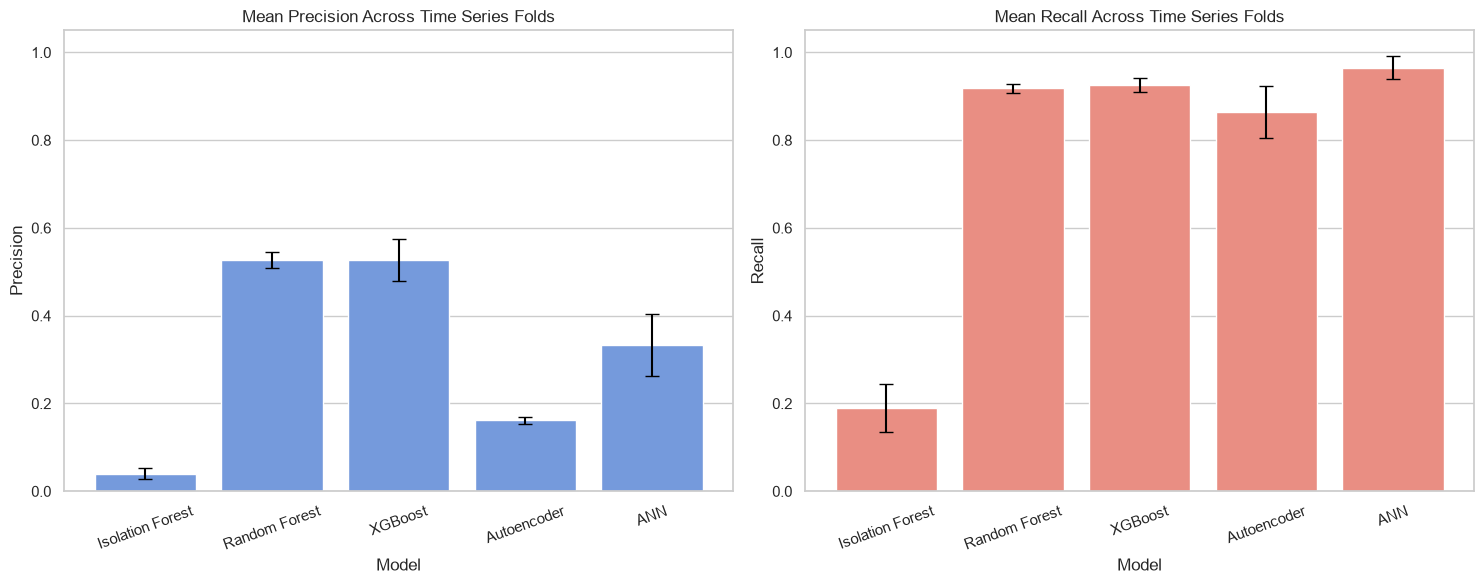

In [8]:
# 8. PRECISION AND RECALL COMPARISON IN TIME SERIES CV

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Precision Mean ± Std
sns.barplot(
    data=cv_results,
    x="Model",
    y="Precision Mean",
    color="cornflowerblue",
    ax=axes[0]
)

axes[0].errorbar(
    x=np.arange(len(cv_results)),
    y=cv_results["Precision Mean"],
    yerr=cv_results["Precision Std"],
    fmt="none",
    color="black",
    capsize=5
)

axes[0].set_title("Mean Precision Across Time Series Folds")
axes[0].set_xlabel("Model")
axes[0].set_ylabel("Precision")
axes[0].set_ylim(0, 1.05)
axes[0].tick_params(axis="x", rotation=20)

# Recall Mean ± Std
sns.barplot(
    data=cv_results,
    x="Model",
    y="Recall Mean",
    color="salmon",
    ax=axes[1]
)

axes[1].errorbar(
    x=np.arange(len(cv_results)),
    y=cv_results["Recall Mean"],
    yerr=cv_results["Recall Std"],
    fmt="none",
    color="black",
    capsize=5
)

axes[1].set_title("Mean Recall Across Time Series Folds")
axes[1].set_xlabel("Model")
axes[1].set_ylabel("Recall")
axes[1].set_ylim(0, 1.05)
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig(
    "../results/figures/time_series_cv_precision_recall.png",
    dpi=300
)
plt.show()